In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests
from matplotlib.lines import Line2D

In [2]:
data = pd.read_table("DNA_FISH_data.txt")
data

,Measurement,ID,Distance,Condition,Rep
0,Shh-ZRS,0,0.272876,NIPBL+,1
1,SBE2-ZRS,0,0.476267,NIPBL+,1
2,Shh-SBE2,0,0.442829,NIPBL+,1
3,Shh-ZRS,0,0.737665,NIPBL-,1
4,SBE2-ZRS,0,0.535396,NIPBL-,1
...,...,...,...,...,...
4584,SBE6-ZRS,104,0.420000,RAD21-,2
4585,Shh-SBE6,104,0.342000,RAD21-,2
4586,Shh-ZRS,105,0.873000,RAD21-,2
4587,SBE6-ZRS,105,0.358000,RAD21-,2


In [3]:
palette=["#83aac3", "#3c627c", "#ea9648", "#c96d18", "#aed6ca", "#305f51"]

/local/55263823.1.igmm_long/ipykernel_1273923/3315746287.py:7: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.violinplot(data=df,


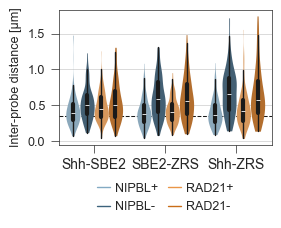

In [4]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.75,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
hue_order = ["NIPBL+", "NIPBL-", "RAD21+", "RAD21-"]
order = ["Shh-SBE2", "SBE2-ZRS", "Shh-ZRS"]
df = data[data["Rep"]==1]
g = sns.violinplot(data=df, 
                   x="Measurement", y="Distance", hue="Condition", palette=palette, 
                   hue_order=hue_order, order=order, cut=0, density_norm="width", 
                   linewidth=0, edgecolor="k", 
                   inner_kws=dict(box_width=3, whis_width=1))
g.set(xlabel="")
g.set_ylabel("Inter-probe distance [µm]", fontsize=9)
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)

handles, labels = g.get_legend_handles_labels()

custom_handles = [
    Line2D([0], [0], color=palette[i], lw=1.0) 
    for i in range(len(hue_order))
]

g.legend(
    handles=custom_handles,
    labels=labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    fontsize=9,
    frameon=False,
    handlelength=1.0,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.axhline(0.35, linestyle="--",zorder=-1, linewidth=0.75, color="k")

In [5]:
pval = pd.DataFrame()
for measure in df["Measurement"].unique():
    for line in ["RAD21", "NIPBL"]:
        x = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}+"), "Distance"].tolist()
        y = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}-"), "Distance"].tolist()
        wc = mannwhitneyu(x, y) 
        pval = pd.concat([pval, pd.DataFrame({"Measurement": [measure], "Line": line, "pval": [wc[1]], "Diff": np.mean(x) / np.mean(y), "N": len(x)})])

mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Measurement"] + "_" + pval["Line"] + "+ vs -"
pval["test"] = "mannwhitneyu"
pval.drop(columns=["Line", "Measurement"]).sort_values("pval")

,pval,Diff,N,padj,sig,log10_p,Condition,test
0,2.370374e-12,0.593434,112,1.422224e-11,True,10.847032,Shh-ZRS_NIPBL+ vs -,mannwhitneyu
0,1.024381e-08,0.664241,113,3.073143e-08,True,7.512417,SBE2-ZRS_NIPBL+ vs -,mannwhitneyu
0,2.279046e-07,0.704802,135,3.658662e-07,True,6.436678,SBE2-ZRS_RAD21+ vs -,mannwhitneyu
0,2.439108e-07,0.684538,135,3.658662e-07,True,6.436678,Shh-ZRS_RAD21+ vs -,mannwhitneyu
0,4.212908e-04,0.823405,113,5.055490e-04,True,3.296237,Shh-SBE2_NIPBL+ vs -,mannwhitneyu
0,1.260258e-01,0.886935,135,1.260258e-01,False,0.899540,Shh-SBE2_RAD21+ vs -,mannwhitneyu


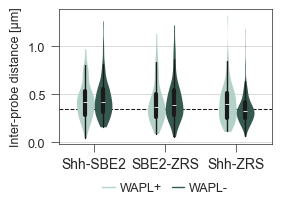

In [6]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.75,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
hue_order = ["WAPL+", "WAPL-"]
order = ["Shh-SBE2", "SBE2-ZRS", "Shh-ZRS"]
df = data[data["Rep"]==1]
g = sns.violinplot(data=df, 
                   x="Measurement", y="Distance", hue="Condition", palette=palette[4:], 
                   hue_order=hue_order, order=order, cut=0, density_norm="width", 
                   linewidth=0, edgecolor="k", width=0.5,
                   inner_kws=dict(box_width=3, whis_width=1))
g.set(xlabel="")
g.set_ylabel("Inter-probe distance [µm]", fontsize=9)
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)

handles, labels = g.get_legend_handles_labels()

custom_handles = [
    Line2D([0], [0], color=palette[i+4], lw=1.0) 
    for i in range(len(hue_order))
]

g.legend(
    handles=custom_handles,
    labels=labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    fontsize=9,
    frameon=False,
    handlelength=1.0,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.axhline(0.35, linestyle="--",zorder=-1, linewidth=0.75, color="k")

In [7]:
pval = pd.DataFrame()
for measure in df["Measurement"].unique():
    for line in ["WAPL"]:
        x = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}+"), "Distance"].tolist()
        y = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}-"), "Distance"].tolist()
        wc = mannwhitneyu(x, y) 
        pval = pd.concat([pval, pd.DataFrame({"Measurement": [measure], "Line": line, "pval": [wc[1]], "Diff": np.mean(x) / np.mean(y), "N": len(x)})])

mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Measurement"] + "_" + pval["Line"] + "+ vs -"
pval["test"] = "mannwhitneyu"
pval.drop(columns=["Line", "Measurement"]).sort_values("pval")

,pval,Diff,N,padj,sig,log10_p,Condition,test
0,0.008779,1.184958,126,0.026338,True,1.579411,Shh-ZRS_WAPL+ vs -,mannwhitneyu
0,0.239357,0.945221,126,0.359036,False,0.444862,SBE2-ZRS_WAPL+ vs -,mannwhitneyu
0,0.568579,0.952751,126,0.568579,False,0.245209,Shh-SBE2_WAPL+ vs -,mannwhitneyu


/local/55263823.1.igmm_long/ipykernel_1273923/1064307024.py:7: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.violinplot(data=df,


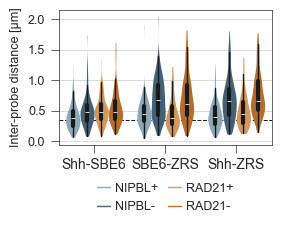

In [8]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.75,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
hue_order = ["NIPBL+", "NIPBL-", "RAD21+", "RAD21-"]
order = ["Shh-SBE6", "SBE6-ZRS", "Shh-ZRS"]
df = data[data["Rep"]==2]
g = sns.violinplot(data=df, 
                   x="Measurement", y="Distance", hue="Condition", palette=palette, 
                   hue_order=hue_order, order=order, cut=0, density_norm="width", 
                   linewidth=0, edgecolor="k", 
                   inner_kws=dict(box_width=3, whis_width=1))
g.set(xlabel="")
g.set_ylabel("Inter-probe distance [µm]", fontsize=9)
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)

handles, labels = g.get_legend_handles_labels()

custom_handles = [
    Line2D([0], [0], color=palette[i], lw=1.0) 
    for i in range(len(hue_order))
]

g.legend(
    handles=custom_handles,
    labels=labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    fontsize=9,
    frameon=False,
    handlelength=1.0,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.axhline(0.35, linestyle="--",zorder=-1, linewidth=0.75, color="k")

In [9]:
pval = pd.DataFrame()
for measure in df["Measurement"].unique():
    for line in ["RAD21", "NIPBL"]:
        x = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}+"), "Distance"].tolist()
        y = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}-"), "Distance"].tolist()
        wc = mannwhitneyu(x, y) 
        pval = pd.concat([pval, pd.DataFrame({"Measurement": [measure], "Line": line, "pval": [wc[1]], "Diff": np.mean(x) / np.mean(y), "N": len(x)})])

mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Measurement"] + "_" + pval["Line"] + "+ vs -"
pval["test"] = "mannwhitneyu"
pval.drop(columns=["Line", "Measurement"]).sort_values("pval")

,pval,Diff,N,padj,sig,log10_p,Condition,test
0,2.422237e-10,0.633830,131,1.239996e-09,True,8.906580,Shh-ZRS_NIPBL+ vs -,mannwhitneyu
0,4.133320e-10,0.660521,131,1.239996e-09,True,8.906580,SBE6-ZRS_NIPBL+ vs -,mannwhitneyu
0,1.316989e-09,0.649888,96,2.633978e-09,True,8.579388,Shh-ZRS_RAD21+ vs -,mannwhitneyu
0,1.266348e-08,0.629649,96,1.899522e-08,True,7.721356,SBE6-ZRS_RAD21+ vs -,mannwhitneyu
0,1.025927e-03,0.817280,131,1.231112e-03,True,2.909702,Shh-SBE6_NIPBL+ vs -,mannwhitneyu
0,6.935272e-01,0.939987,96,6.935272e-01,False,0.158936,Shh-SBE6_RAD21+ vs -,mannwhitneyu


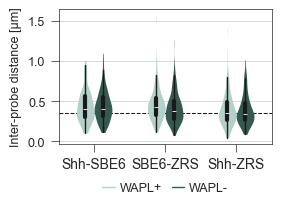

In [10]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.75,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
hue_order = ["WAPL+", "WAPL-"]
order = ["Shh-SBE6", "SBE6-ZRS", "Shh-ZRS"]
df = data[data["Rep"]==2]
g = sns.violinplot(data=df, 
                   x="Measurement", y="Distance", hue="Condition", palette=palette[4:], 
                   hue_order=hue_order, order=order, cut=0, density_norm="width", 
                   linewidth=0, edgecolor="k", width=0.5,
                   inner_kws=dict(box_width=3, whis_width=1))
g.set(xlabel="")
g.set_ylabel("Inter-probe distance [µm]", fontsize=9)
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)


handles, labels = g.get_legend_handles_labels()

custom_handles = [
    Line2D([0], [0], color=palette[i+4], lw=1.0) 
    for i in range(len(hue_order))
]

g.legend(
    handles=custom_handles,
    labels=labels,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.2),
    ncol=2,
    fontsize=9,
    frameon=False,
    handlelength=1.0,
    columnspacing=0.8,
    handletextpad=0.4
)

plt.axhline(0.35, linestyle="--",zorder=-1, linewidth=0.75, color="k")


In [11]:
pval = pd.DataFrame()
for measure in df["Measurement"].unique():
    for line in ["WAPL"]:
        x = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}+"), "Distance"].tolist()
        y = df.loc[(df["Measurement"] == measure) & (df["Condition"] == f"{line}-"), "Distance"].tolist()
        wc = mannwhitneyu(x, y) 
        pval = pd.concat([pval, pd.DataFrame({"Measurement": [measure], "Line": line, "pval": [wc[1]], "Diff": np.mean(x) / np.mean(y), "N": len(x)})])

mh = multipletests(pval["pval"], alpha=0.05, method='fdr_bh')
pval["padj"] = mh[1]
pval["sig"] = mh[0]
pval["log10_p"] = -np.log10(pval["padj"])
pval["Condition"] = pval["Measurement"] + "_" + pval["Line"] + "+ vs -"
pval["test"] = "mannwhitneyu"
pval.drop(columns=["Line", "Measurement"]).sort_values("pval")

,pval,Diff,N,padj,sig,log10_p,Condition,test
0,0.062345,1.084779,148,0.187034,False,0.72808,SBE6-ZRS_WAPL+ vs -,mannwhitneyu
0,0.750038,0.989590,148,0.830595,False,0.08061,Shh-SBE6_WAPL+ vs -,mannwhitneyu
0,0.830595,1.011013,148,0.830595,False,0.08061,Shh-ZRS_WAPL+ vs -,mannwhitneyu


In [12]:
data["<350nm"] = np.where(data["Distance"] <= .350, True, False)
fishprop = data.groupby(["Measurement", "Condition", "Rep", "<350nm"]).size().reset_index()
fishprop["Proportion"] = fishprop[0] / fishprop.groupby(["Measurement", "Condition", "Rep"]).transform("sum")[0]
fishprop = fishprop[fishprop["<350nm"]].drop(columns=[0, "<350nm"])
fish_median_prop = data.groupby(["Measurement", "Condition", "Rep"]).median(numeric_only=True).reset_index().drop(columns=["<350nm", "ID"]).merge(fishprop)
fish_median_prop.to_csv("DNA_FISH_data_median_prop.txt", sep="\t", index=False)

/local/55263823.1.igmm_long/ipykernel_1273923/3694285366.py:6: UserWarning: The palette list has more values (6) than needed (4), which may not be intended.
  g = sns.barplot(data=fishprop,


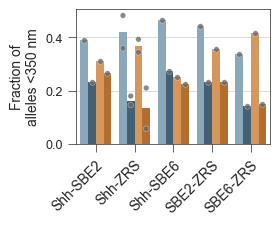

In [13]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(2.5,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
order = ["Shh-SBE2", "Shh-ZRS",  "Shh-SBE6", "SBE2-ZRS", "SBE6-ZRS"]
hue_order = ["NIPBL+", "NIPBL-", "RAD21+", "RAD21-"]
g = sns.barplot(data=fishprop, 
                hue="Condition", x="Measurement", y="Proportion",
                edgecolor="k", linewidth=0, alpha=1, width=0.8, 
                errorbar=None, order=order, hue_order=hue_order, legend=False,
                palette=palette)
sns.stripplot(data=fishprop, 
                hue="Condition", x="Measurement", y="Proportion",
                edgecolor="white", linewidth=0.25, alpha=0.8, s=4, legend=False,
                order=order, hue_order=hue_order, dodge=True, jitter=0, 
                palette=["dimgrey"]*4, ax=g)
g.set(xlabel="")
g.set_ylabel("Fraction of\nalleles <350 nm", fontsize=10)
plt.xticks(rotation=45, rotation_mode="anchor", ha="right")
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)

/local/55263823.1.igmm_long/ipykernel_1273923/2442585970.py:11: UserWarning: The palette list has more values (4) than needed (2), which may not be intended.
  sns.stripplot(data=fishprop,


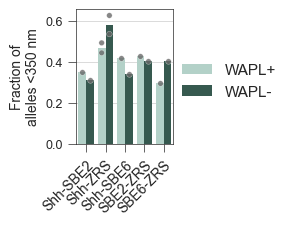

In [14]:
sns.set(style="ticks", font="Arial", rc={'figure.figsize':(1.25,1.75), "axes.linewidth": 0.5, 
                                         "xtick.major.width": 0.5, "ytick.major.width": 0.5,
                                         "xtick.minor.width": 0.5, "ytick.minor.width": 0.5})
order = ["Shh-SBE2", "Shh-ZRS",  "Shh-SBE6", "SBE2-ZRS", "SBE6-ZRS"]
hue_order = ["WAPL+", "WAPL-"]
g = sns.barplot(data=fishprop, 
                hue="Condition", x="Measurement", y="Proportion",
                edgecolor="k", linewidth=0, alpha=1, width=0.8, 
                errorbar=None, order=order, hue_order=hue_order,
                palette=palette[4:6], legend=True)
sns.stripplot(data=fishprop, 
                hue="Condition", x="Measurement", y="Proportion",
                edgecolor="white", linewidth=0.25, alpha=0.8, s=4, legend=False,
                order=order, hue_order=hue_order, dodge=True, jitter=0, 
                palette=["dimgrey"]*4, ax=g)
g.set(xlabel="")
g.set_ylabel("Fraction of\nalleles <350 nm", fontsize=10)
sns.move_legend(g, loc="upper right", bbox_to_anchor=(2.2,0.7), frameon=False, title="")
plt.xticks(rotation=45, rotation_mode="anchor", ha="right")
g.tick_params(axis='y', labelsize=9)
g.tick_params(axis='x', labelsize=10)
g.grid(True, axis="y", linewidth=0.5)